In [8]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier

from sklearn.feature_selection import f_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv(Path("/mnt/data/datasets/spotify_tracks/tracks.csv"))

## 1.1 Data Exploration

In [3]:
df.head()

,Unnamed: 0,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,...,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
0,0,"Divenire: No. 9, Fly - Intouchables",5u5scm02d5wN6nWFKuqEUK,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,...,0.0996,-28.184,0,0.0366,168.133,3,0.0351,0,265.653,4.427550
1,1,Spiegel im Spiegel - Heaven,1wV4SNFEXWawsyjBCGwkiw,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,...,0.0669,-30.646,1,0.0375,136.864,5,0.0394,0,349.120,5.818667
2,2,Truman Sleeps - The Trumanshow,4gYub3T80gNfU9F4Df98AR,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,...,0.1390,-24.620,0,0.0395,69.487,4,0.0411,0,128.039,2.133983
3,3,The Heart Askes Pleasure First - The Piano,6sXRgSAQsySTM7kH1pM07Y,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,...,0.1010,-19.591,0,0.0371,165.197,3,0.1710,0,190.960,3.182667
4,4,3 Gymnopédies: I. Lent et douloureux,7Eytd0e0mNFiSWIE132H76,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,...,0.0817,-37.782,1,0.2860,134.237,3,0.5080,0,338.933,5.648883


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2112746 entries, 0 to 2112745
Data columns (total 30 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0   Unnamed: 0                    int64  
 1   track_name                    str    
 2   track_id                      str    
 3   album_name                    str    
 4   album_id                      str    
 5   album_image                   str    
 6   album_release_date            str    
 7   album_release_date_precision  str    
 8   artist_name                   str    
 9   artist_id                     str    
 10  popularity                    int64  
 11  duration_ms                   int64  
 12  explicit                      bool   
 13  preview_url                   str    
 14  genre                         str    
 15  acousticness                  float64
 16  danceability                  float64
 17  energy                        float64
 18  instrumentalness              flo

In [3]:
df = df.drop(columns="Unnamed: 0")

In [6]:
df.describe()

,popularity,duration_ms,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
count,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06,2.112746e+06
mean,1.377674e+01,2.494334e+05,3.921934e-01,5.285378e-01,5.833886e-01,2.188477e-01,5.248916e+00,2.245101e-01,-1.025284e+01,6.620711e-01,8.521999e-02,1.202604e+02,3.873687e+00,4.874512e-01,4.446996e+01,2.494334e+02,4.157224e+00
std,1.463674e+01,1.453017e+05,3.669647e-01,1.797404e-01,2.759473e-01,3.469541e-01,3.532847e+00,2.025179e-01,5.799937e+00,4.730043e-01,1.185053e-01,2.977373e+01,4.701891e-01,2.726178e-01,3.142499e+01,1.453017e+02,2.421696e+00
min,0.000000e+00,4.860000e+02,0.000000e+00,0.000000e+00,1.970000e-05,0.000000e+00,0.000000e+00,2.960000e-03,-5.810000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.860000e-01,8.100000e-03
25%,1.000000e+00,1.795010e+05,2.210000e-02,4.040000e-01,3.700000e-01,1.180000e-06,2.000000e+00,9.770000e-02,-1.290100e+01,0.000000e+00,3.570000e-02,9.711000e+01,4.000000e+00,2.560000e-01,1.600000e+01,1.795010e+02,2.991683e+00
50%,9.000000e+00,2.268865e+05,2.890000e-01,5.390000e-01,6.130000e-01,8.260000e-04,5.000000e+00,1.370000e-01,-8.900000e+00,1.000000e+00,4.720000e-02,1.199840e+02,4.000000e+00,4.840000e-01,4.000000e+01,2.268865e+02,3.781442e+00
75%,2.200000e+01,2.878800e+05,7.600000e-01,6.630000e-01,8.260000e-01,4.060000e-01,8.000000e+00,2.910000e-01,-6.117000e+00,1.000000e+00,7.850000e-02,1.385590e+02,4.000000e+00,7.150000e-01,7.000000e+01,2.878800e+02,4.798000e+00
max,1.000000e+02,7.200006e+06,9.960000e-01,9.950000e-01,1.000000e+00,1.000000e+00,1.100000e+01,1.000000e+00,6.172000e+00,1.000000e+00,9.690000e-01,2.499930e+02,5.000000e+00,1.000000e+00,1.120000e+02,7.200006e+03,1.200001e+02


In [7]:
df.isnull().sum()

track_name                           6
track_id                             0
album_name                           6
album_id                             0
album_image                        491
album_release_date                   0
album_release_date_precision         0
artist_name                         17
artist_id                            0
popularity                           0
duration_ms                          0
explicit                             0
preview_url                     325237
genre                                0
acousticness                         0
danceability                         0
energy                               0
instrumentalness                     0
key                                  0
liveness                             0
loudness                             0
mode                                 0
speechiness                          0
tempo                                0
time_signature                       0
valence                  

In [10]:
print(df['genre'].value_counts().to_string())

genre
classical            48143
blues                45752
indian               43616
german               43002
french               40832
country              38847
british              38476
alt-rock             37065
disco                34808
brazil               34482
opera                34056
turkish              33997
pop-film             32269
dance                32059
jazz                 31340
ambient              30898
gospel               30422
latin                30368
spanish              30298
folk                 29167
funk                 28505
guitar               27087
bluegrass            27073
k-pop                26457
j-pop                26114
swedish              25838
dub                  25670
acoustic             25669
children             25597
new-age              25164
mpb                  25108
anime                24623
black-metal          23511
dancehall            23477
forro                23266
cantopop             23036
death-metal          2

In [4]:
df = df.drop(columns=['database_shard_id', 'preview_url', 'album_name', 'album_id', 'track_name', 'track_id', 'album_image', 'album_release_date', 'album_release_date_precision', 'artist_name', 'artist_id', 'duration_ms', 'duration_minutes'])

In [5]:
le = LabelEncoder()

df['genre'] = le.fit_transform(df["genre"])
df['explicit'] = df['explicit'].astype(int)

df = df.drop(columns="popularity")

The **popularity** feature was removed, as it does not characterize a song in purely technical terms. Furthermore, including this feature could introduce bias into the model.

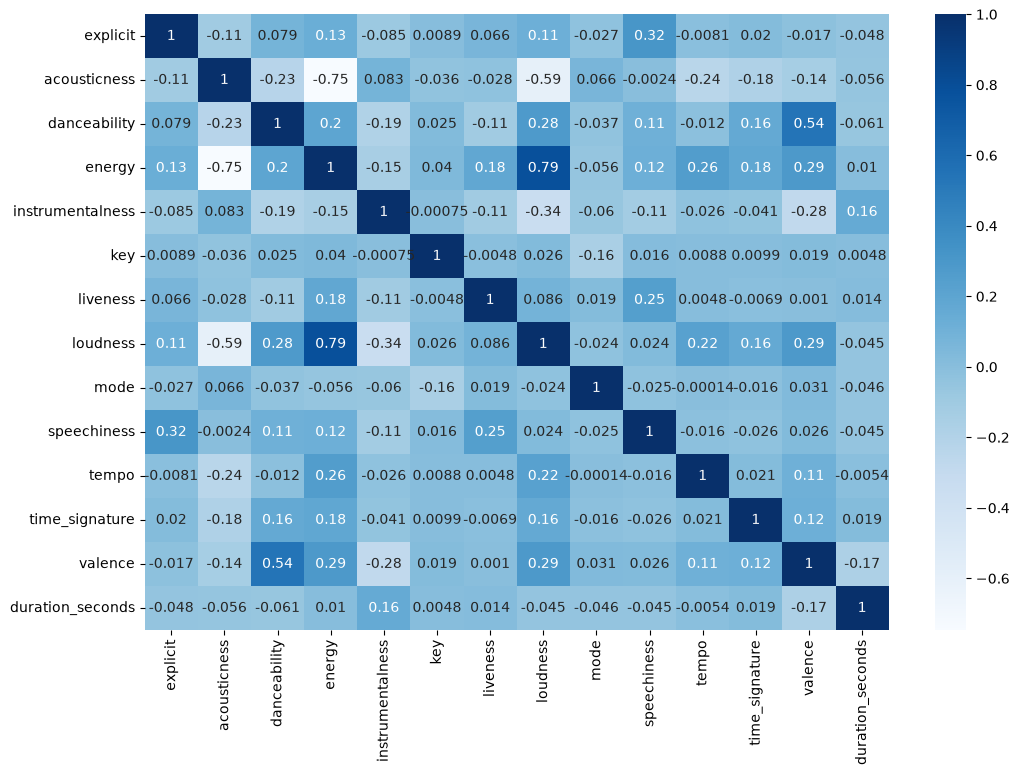

In [12]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.drop(columns='genre').select_dtypes(include='number').corr(),
    annot=True,
    cmap='Blues'
)

plt.show()

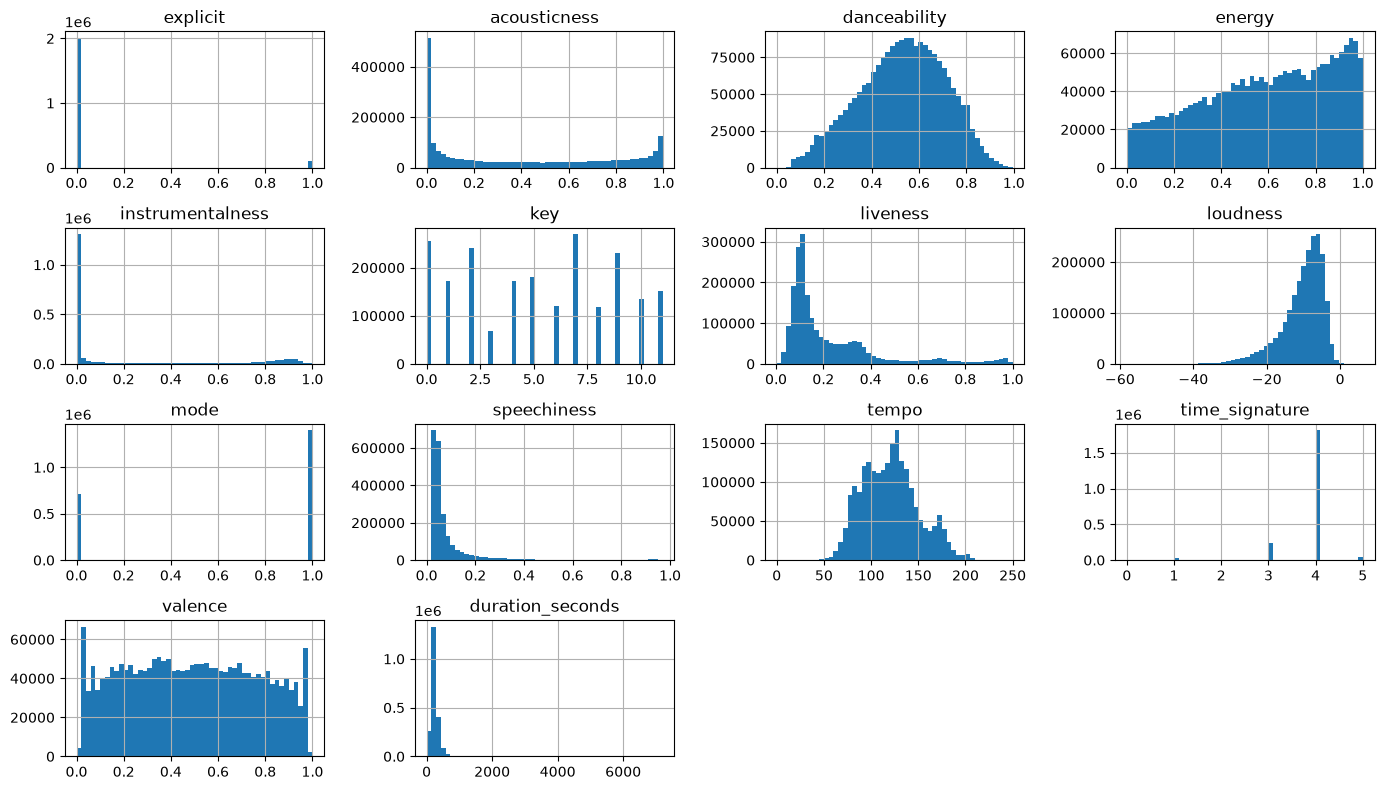

In [6]:
df.drop(columns='genre').hist(bins=50, figsize=(14, 8))

plt.tight_layout()
plt.show()

On the histograms figure above we can see that some features have a certain skewness, either positive if the data is skewed to the left, and negative if skewed to the right.

- duration_seconds: positive
- loudness: negative
- liveness: positive
- energy: negative

Acousticness doesn't seem normally distributed, we will investigate this in the next step.

In [7]:
df['liveness'].describe()

count    2.112746e+06
mean     2.245101e-01
std      2.025179e-01
min      2.960000e-03
25%      9.770000e-02
50%      1.370000e-01
75%      2.910000e-01
max      1.000000e+00
Name: liveness, dtype: float64

In [12]:
df.skew(numeric_only=True)

explicit            4.167169
genre               0.268192
acousticness        0.372815
danceability       -0.218408
energy             -0.324786
instrumentalness    1.193549
key                -0.001305
liveness            1.960642
loudness           -1.393420
mode               -0.685284
speechiness         4.772691
tempo               0.360187
time_signature     -3.139470
valence             0.047029
duration_seconds    8.492912
dtype: float64

In [26]:
from sklearn.preprocessing import PowerTransformer

transformer = PowerTransformer(
    method="yeo-johnson",
    standardize=True
)

x_transformed = transformer.fit_transform(
    df[["liveness"]].dropna()
)

In [19]:
mask = df["liveness"].notna()

df.loc[mask, "liveness"] = x_transformed.ravel()

In [16]:
df['liveness'] = np.log1p(df['liveness'])

In [6]:
scaler = StandardScaler()

In [9]:
df['liveness'] = scaler.fit_transform(df[['liveness']])

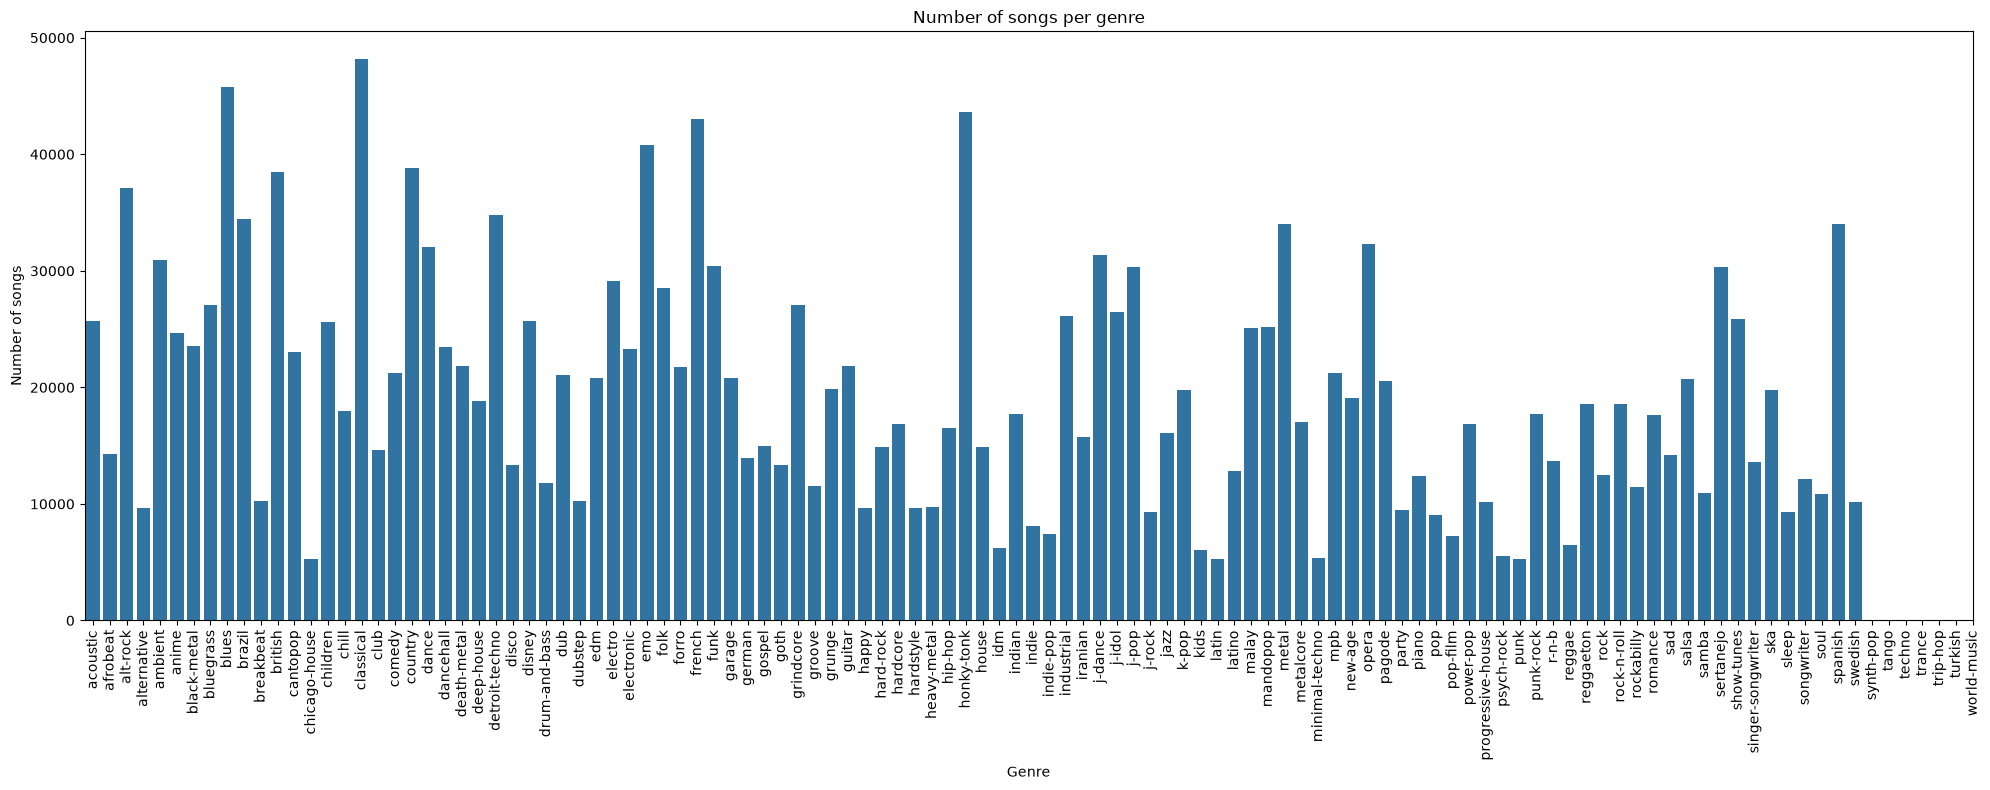

In [61]:
plt.figure(figsize=(20, 8))

ax = sns.countplot(x="genre", data=df)

ax.set_xticks(range(len(le.classes_)))
ax.set_xticklabels(le.classes_, rotation=90)

plt.xlabel("Genre")
plt.ylabel("Number of songs")
plt.title("Number of songs per genre")

plt.tight_layout()
plt.show()

## 1.2 Data Preparation

In [6]:
X = df.drop(columns="genre")
y = df["genre"]

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### 1.2.1 Correlation

In the next step we calculate the **ANOVA correlation coefficient**, as our input variables are numerical and output variables are non-ordinal categorical. This informs us what features correlate highly with the output variable, genre.

In [80]:
f_statistic, p_values = f_classif(X, y)

anova_df = pd.DataFrame({
    "feature": X.columns,
    "F-value": f_statistic,
    "p-value": p_values
}).sort_values("F-value", ascending=False)

anova_df

,feature,F-value,p-value
1,acousticness,16170.926082,0.0
9,speechiness,13469.185535,0.0
3,energy,13468.240207,0.0
7,loudness,12467.363336,0.0
2,danceability,10149.658656,0.0
4,instrumentalness,10003.960940,0.0
12,valence,7546.817098,0.0
0,explicit,4514.662127,0.0
13,duration_seconds,2067.722999,0.0
6,liveness,1640.138417,0.0


The highest F-values observed are *acousticness*, *speechiness* and *energy*

### 1.2.2 Multicollinearity

We calculate the **Variance Inflation Factor** (VIF) to detect multicollinearity between the numerical input variables. This indicates whether some features contain overlapping information, and could therefore mislead the model.

In [85]:
vif_df = pd.DataFrame({
    "feature": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
}).sort_values("VIF", ascending=False)

vif_df

,feature,VIF
3,energy,4.809132
7,loudness,3.277149
1,acousticness,2.542634
12,valence,1.719218
2,danceability,1.660272
4,instrumentalness,1.307025
9,speechiness,1.271695
6,liveness,1.161211
0,explicit,1.142851
10,tempo,1.103577


A VIF value equal to 1 indicates no multicollinearity, while a VIF between 1 and 5 indicates a moderate level of multicollinearity. A VIF greater than 5 indicates potentially problematic multicollinearity.

The highest VIF values were observed for *energy* and *loudness*. Both values are below the threshold of 5, indicating that there is no significant multicollinearity between the input features. Therefore, both features can remain in the dataset.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, stratify=y, random_state=42)

## 2.1 Model training

In [ ]:
lr_model = LogisticRegression(
        solver="lbfgs",
        max_iter=200
)

lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](106,)","[ 0, 1, 2,...,110,111,112]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['explicit','acousticness','danceability',...,'time_signature','valence', 'duration_seconds']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [11]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

rf_model.fit(X_train, y_train)

KeyboardInterrupt: 

In [9]:
cb_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.1,
    depth=6,
    loss_function="MultiClass",
    eval_metric="Accuracy",
    random_seed=42,
    verbose=50,
    task_type="GPU",
    devices="0"
)

cb_model.fit(X_train, y_train)

0:	learn: 0.0865769	total: 447ms	remaining: 2m 13s
50:	learn: 0.1843212	total: 19.1s	remaining: 1m 33s
100:	learn: 0.1996141	total: 37.7s	remaining: 1m 14s
150:	learn: 0.2089900	total: 56.3s	remaining: 55.5s
200:	learn: 0.2150904	total: 1m 14s	remaining: 36.9s
250:	learn: 0.2198668	total: 1m 33s	remaining: 18.2s
299:	learn: 0.2236220	total: 1m 51s	remaining: 0us


CatBoostClassifier(depth=6, devices='0', eval_metric='Accuracy', iterations=300, learning_rate=0.1, loss_function='MultiClass', random_seed=42, task_type='GPU', verbose=50)

## 2.2 Model evaluation

In [10]:
y_pred = cb_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2f}")

Model Accuracy: 0.22
